# Pilotage énergétique par RL – 3. L'agent

**Le problème posé à l'agent.** Chaque heure, il voit l'heure, la couleur du jour et celle du lendemain (dès 11 h), le niveau du ballon et de la batterie, le solaire des 6 prochaines heures et les prix à venir. Il choisit 1 action sur 6 : chauffer ou non le ballon, et mettre la batterie en autoconsommation, en charge ou en conservation. Sa récompense est la facture de l'heure, en négatif, moins 3 € par kWh d'eau chaude manquante.

**L'algorithme.** PPO (Stable-Baselines3), un réseau de 2 × 128 neurones. Deux façons de l'entraîner ont été comparées :
1. **v1, à partir de zéro** (`train.py`) : 1,5 million d'heures simulées, avec une première version des indicateurs (sans les prix à venir ni la prévision solaire du lendemain).
2. **Version finale, imitation puis RL** (`train_v3.py`, modèle `ppo_v4`) : le réseau apprend d'abord à reproduire la règle experte sur les 7 saisons d'entraînement, puis PPO l'améliore pendant 2 millions d'heures. L'agent voit aussi les prix à venir et la prévision solaire du lendemain. Le meilleur modèle est choisi sur 2021-2022.

Une sécurité de thermostat force la chauffe sous 1 kWh, pour tous les pilotes.

La saison 2022-2023 n'a servi à rien pendant l'entraînement : c'est le test.

In [1]:
import sys, json; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from stable_baselines3 import PPO
from energy_env import Maison, charger_donnees, simuler, bilan, REGLES
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
MOD = "../modeles"
df = charger_donnees(); m = Maison(df)
agent = PPO.load(f"{MOD}/ppo_v4_meilleur", device="cpu")
def saison(s):
    pos = np.where(df.saison == s)[0]; return int(pos[0]), int(pos[-1]) + 1

## 1. L'apprentissage

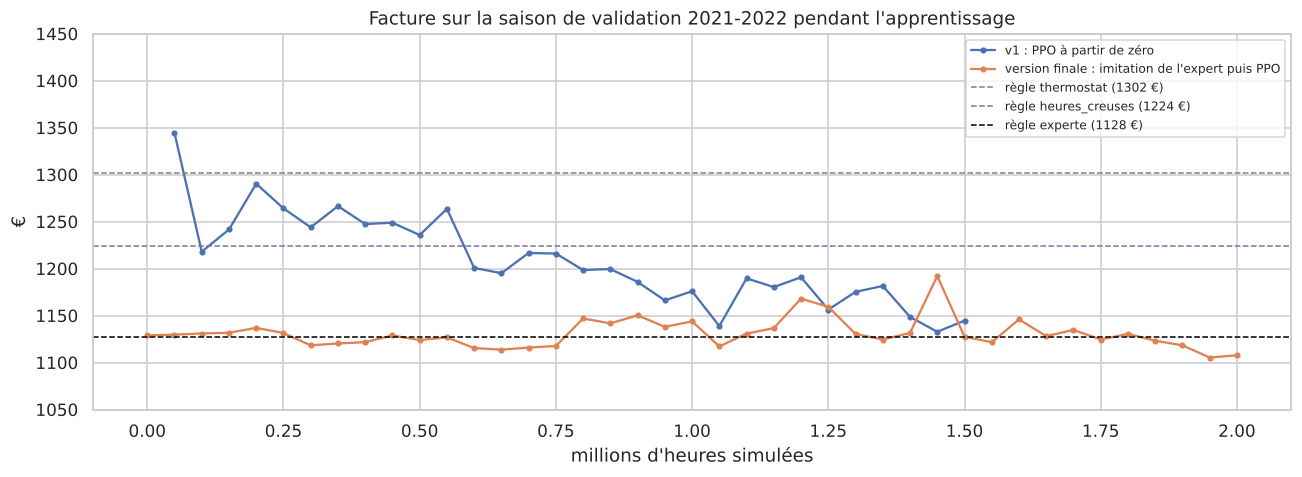

v1 : meilleure facture 1132.7 € | eau froide à ce point : 27 h
version finale : facture après imitation 1128.8 € | meilleur score 1110.0 à 1950000 pas


In [2]:
h1 = pd.DataFrame(json.load(open(f"{MOD}/ppo_v1_historique.json")))
h3 = pd.DataFrame(json.load(open(f"{MOD}/ppo_v4_historique.json")))
a, b = saison("2021-2022")
ref = {k: bilan(simuler(m, a, b, f), m)["facture_eur"] for k, f in REGLES.items()}
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(h1.pas / 1e6, h1.facture_eur, marker=".", label="v1 : PPO à partir de zéro")
ax.plot(h3.pas / 1e6, h3.facture_eur, marker=".", label="version finale : imitation de l'expert puis PPO")
for k, c in zip(ref, ["grey", "#8172b2", "black"]):
    ax.axhline(ref[k], ls="--", color=c, lw=1, label=f"règle {k} ({ref[k]:.0f} €)")
ax.set(title="Facture sur la saison de validation 2021-2022 pendant l'apprentissage", xlabel="millions d'heures simulées", ylabel="€", ylim=(1050, 1450))
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()
print("v1 : meilleure facture", h1.facture_eur.min(), "€ | eau froide à ce point :", int(h1.loc[h1.score.idxmin(), "eau_froide_h"]), "h")
print("version finale : facture après imitation", h3.facture_eur.iloc[0], "€ | meilleur score", h3.score.min(), "à", int(h3.loc[h3.score.idxmin(), "pas"]), "pas")

**Lecture.**
- **v1, à partir de zéro :** l'agent part de très haut (1 344 € à 50 000 heures). Il passe sous le thermostat (1 302 €), puis sous le contacteur heures creuses (1 224 €), mais plafonne vers 1 133 € après 1,5 million d'heures, avec 27 heures d'eau froide. Il n'atteint jamais la règle experte.
- **Version finale, imitation puis RL :** l'agent reproduit d'abord l'expert (98,4 % de décisions identiques, 1 129 €). Ensuite PPO l'améliore jusqu'à 1 105 € (score de 1 110 € avec la pénalité d'eau froide), à 1,95 million d'heures.
- **Ce qui a débloqué la situation : la durée, pas la prévision.** J'avais attribué le progrès à la prévision solaire du lendemain, ajoutée au même moment. Le contrôle de la section 5 le dément : entraîné exactement pareil sans cette prévision, l'agent décroche de l'expert après 650 000 heures et atteint 1 107 € en validation. L'essai précédent sans elle, avec les mêmes réglages, avait été arrêté à 350 000 heures, juste avant. La prévision a peut-être accéléré l'apprentissage (décrochage dès 300 000 heures), mais elle n'explique pas le résultat.
- **Pourquoi la courbe est bruitée :** le score est celui d'une saison entière, et une petite modification de la politique déplace des centaines de décisions. On garde le meilleur modèle sur la validation.

## 2. Le résultat sur la saison test 2022-2023

In [3]:
res, traces = {}, {}
for s in ["2021-2022", "2022-2023"]:
    a, b = saison(s)
    for nom, f in {**REGLES, "agent RL": agent}.items():
        r = simuler(m, a, b, f); traces[(s, nom)] = r; res[(s, nom)] = bilan(r, m)
tab = pd.DataFrame(res).T; tab.index.names = ["saison", "pilote"]
for s in ["2021-2022", "2022-2023"]:
    th, ex = tab.loc[(s, "thermostat"), "facture_eur"], tab.loc[(s, "experte"), "facture_eur"]
    tab.loc[s, "gain_vs_thermostat_%"] = (100 * (1 - tab.loc[s, "facture_eur"] / th)).round(1).values
    tab.loc[s, "gain_vs_experte_eur"] = (ex - tab.loc[s, "facture_eur"]).round(1).values
tab

facture_eur  achat_kwh  rouge_hp_kwh  autoconso_pct  \
saison    pilote                                                                
2021-2022 thermostat           1301.6     6432.0         464.3           87.6   
          heures_creuses       1224.4     6611.0         358.8           80.7   
          experte              1127.6     6414.0         258.0           86.9   
          agent RL             1105.3     6139.0         248.1           93.9   
2022-2023 thermostat           1411.2     7213.0         438.1           87.0   
          heures_creuses       1329.2     7320.0         341.2           81.6   
          experte              1252.2     7218.0         249.6           85.5   
          agent RL             1243.7     7014.0         248.7           91.1   

                          eau_froide_h  eau_froide_kwh  gain_vs_thermostat_%  \
saison    pilote                                                               
2021-2022 thermostat               0.0            0.00                   0.0   
          heures_creuses          25.0            1.53                   5.9   
          experte                 15.0            0.81                  13.4   
          agent RL                27.0            1.56                  15.1   
2022-2023 thermostat               0.0            0.00                   0.0   
          heures_creuses          10.0            0.21                   5.8   
          experte                  8.0            0.16                  11.3   
          agent RL                 4.0            0.11                  11.9   

                          gain_vs_experte_eur  
saison    pilote                               
2021-2022 thermostat                   -174.0  
          heures_creuses                -96.8  
          experte                         0.0  
          agent RL                       22.3  
2022-2023 thermostat                   -159.0  
          heures_creuses                -77.0  
          experte                         0.0  
          agent RL                        8.5

**Lecture (saison test 2022-2023, jamais vue).**

| Pilote | Facture | vs thermostat | vs contacteur HC | vs règle experte |
|---|---|---|---|---|
| Thermostat (maison réelle) | 1 411 € | – | | |
| Contacteur heures creuses | 1 329 € | −5,8 % | – | |
| Règle experte | 1 252 € | −11,3 % | −5,8 % | – |
| **Agent RL** | **1 244 €** | **−11,9 %** | **−6,4 %** | **−8,5 € (−0,7 %)** |
| Optimum théorique (tout le futur connu) | 1 131 € | −19,9 % | | |

- **Gain réel :** 168 € par an face au thermostat. L'agent fait à peine mieux que la règle experte : il ne rattrape que 7 % de l'écart entre l'expert et l'optimum théorique.
- **Comment il gagne :** il achète 204 kWh de moins (7 014 contre 7 218) et autoconsomme 91,1 % du solaire contre 85,5 %. Les heures pleines rouges restent au même niveau (249 kWh).
- **Confort :** 4 heures d'eau tiède dans l'année, pour 0,11 kWh manquant.
- **Écart avec l'objectif de départ :** la cible était −10 % face au contacteur heures creuses, on obtient −6,4 %. Elle n'est pas atteinte.

## 3. Ce que l'agent fait différemment

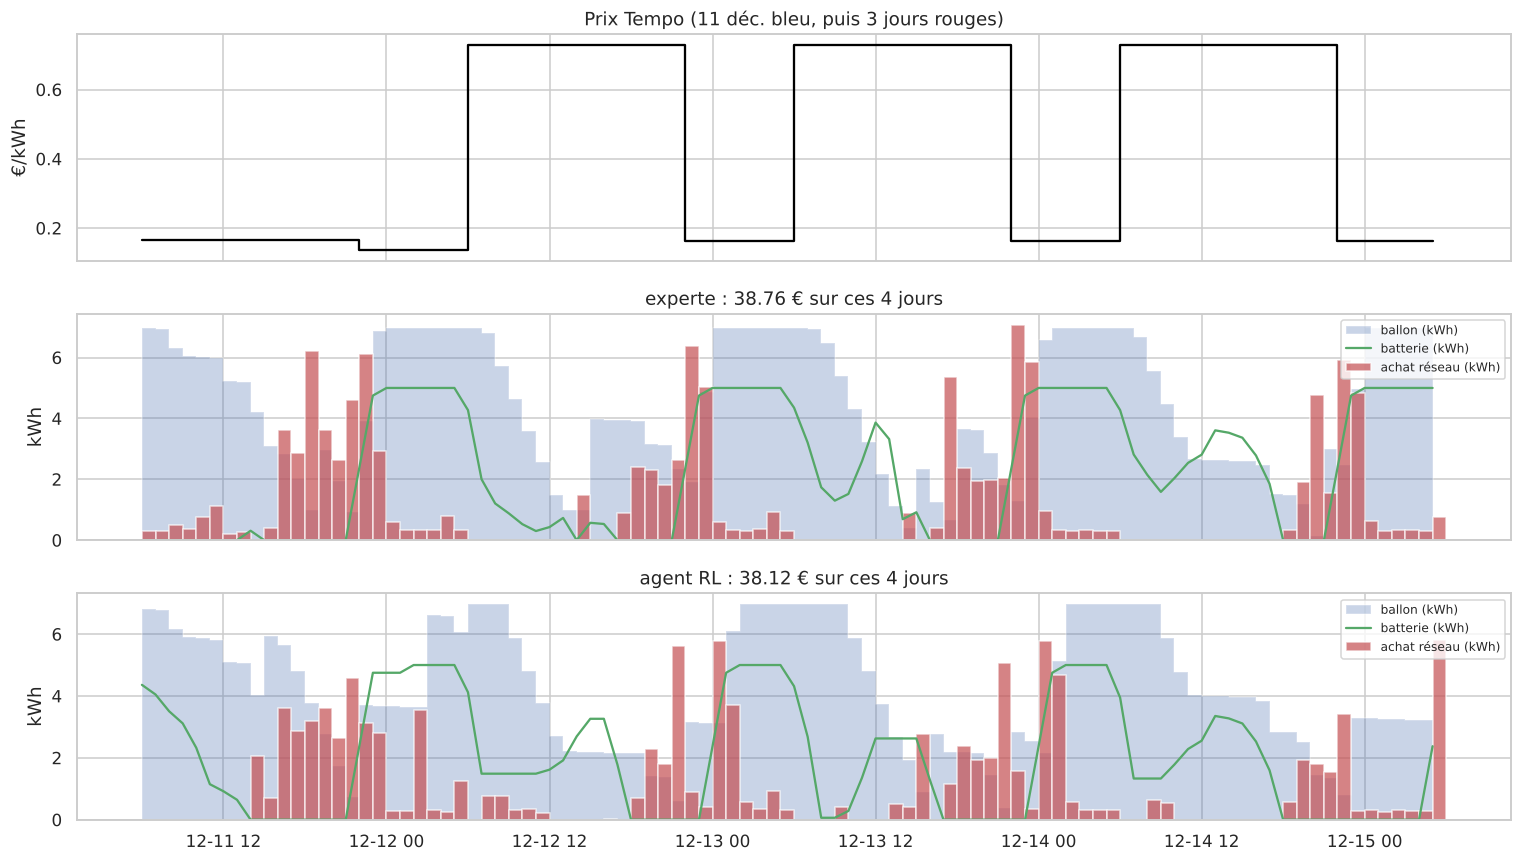

experte : 35.1 kWh achetés en heures pleines rouges, dont 26.1 kWh entre 18 h et 22 h
agent RL : 36.4 kWh achetés en heures pleines rouges, dont 27.6 kWh entre 18 h et 22 h


In [4]:
fin = slice(pd.Timestamp("2022-12-11 06:00"), pd.Timestamp("2022-12-15 05:00"))
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
d = df.loc[fin]
axes[0].step(d.index, d.prix, where="post", color="black"); axes[0].set(ylabel="€/kWh", title="Prix Tempo (11 déc. bleu, puis 3 jours rouges)")
for ax, nom in zip(axes[1:], ["experte", "agent RL"]):
    r = traces[("2022-2023", nom)].loc[fin]
    ax.fill_between(r.index, r.ballon, step="post", alpha=.3, label="ballon (kWh)")
    ax.bar(r.index, r.achat, width=1 / 24, align="edge", color="#c44e52", alpha=.7, label="achat réseau (kWh)")
    ax.plot(r.index, r.soc, color="#55a868", label="batterie (kWh)")
    ax.set(title=f"{nom} : {r.cout.sum():.2f} € sur ces 4 jours", ylabel="kWh"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()
for nom in ["experte", "agent RL"]:
    r = traces[("2022-2023", nom)].loc[fin]; dd = df.loc[r.index]
    rhp = (dd.tempo == "rouge") & ~dd.hc
    print(f"{nom} : {r.achat[rhp].sum():.1f} kWh achetés en heures pleines rouges, dont {r.achat[rhp & (dd.index.hour >= 18)].sum():.1f} kWh entre 18 h et 22 h")

**Lecture.** Sur ces 4 jours, l'agent (38,12 €) et l'expert (38,76 €) font presque pareil, mais pas de la même façon.
- **Le défaut visible :** l'agent fait de petites relances du ballon tôt le matin des jours rouges. Sur la saison, entre 6 h et 8 h, il chauffe 30,5 kWh, dont 21 kWh achetés au réseau, soit 15,3 € contre 1,5 € pour l'expert.
- **Pourquoi on ne le corrige pas à la main :** lui interdire après coup de chauffer en heure pleine rouge dégrade son résultat de 5 € sur la saison (1 248,6 € au lieu de 1 243,7 €). Ses décisions forment un tout. La bonne correction serait de réentraîner avec cette contrainte.

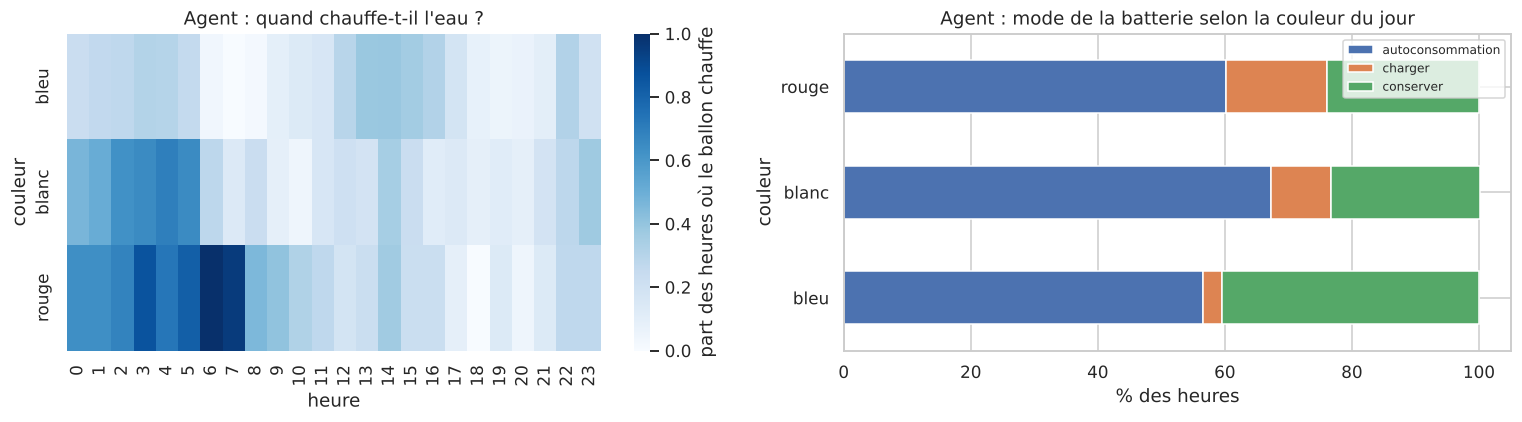

In [5]:
r = traces[("2022-2023", "agent RL")]; d = df.loc[r.index]
x = pd.DataFrame({"heure": d.index.hour, "couleur": d.tempo.values, "chauffe": ((r.action // 3 == 1) | (r.ballon < 1.0)).values,
                  "mode": (r.action % 3).map({0: "autoconsommation", 1: "charger", 2: "conserver"}).values})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x.pivot_table(index="couleur", columns="heure", values="chauffe", aggfunc="mean").loc[["bleu", "blanc", "rouge"]].pipe(
    sns.heatmap, ax=axes[0], cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "part des heures où le ballon chauffe"})
axes[0].set(title="Agent : quand chauffe-t-il l'eau ?")
pd.crosstab([x.couleur], x["mode"], normalize="index").loc[["bleu", "blanc", "rouge"]].mul(100).round(1).plot.barh(stacked=True, ax=axes[1])
axes[1].set(title="Agent : mode de la batterie selon la couleur du jour", xlabel="% des heures"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.**
- **Chauffe :** l'agent chauffe surtout la nuit (heures creuses) les jours blancs et rouges, et vers midi les jours bleus, quand le solaire produit (13 h - 16 h). Les heures 0 h - 6 h comptées « rouges » sont la nuit qui suit un jour rouge, au tarif heures creuses.
- **Batterie :** les jours bleus, l'agent la laisse en *conserver* 40 % du temps, pour garder le solaire pour plus tard au lieu de la vider tout de suite. Les jours rouges, il la *charge* 16 % du temps, la nuit avant les heures pleines.
- **Ce qui le distingue de l'expert :** il chauffe beaucoup moins la nuit (2,3 à 4,4 kWh par nuit en moyenne selon le soleil du lendemain, contre 4,5 à 6,1 pour l'expert). Il garde de la place dans le ballon pour le solaire de la journée, d'où 91 % d'autoconsommation contre 85,5 %. Les deux pilotes chauffent moins la nuit quand le lendemain est ensoleillé (corrélation de −0,31 et −0,33).

## 4. Est-ce que ça tient sur toutes les saisons ?

In [6]:
lignes = []
for s in sorted(df.saison.unique()):
    a, b = saison(s)
    ex = bilan(simuler(m, a, b, REGLES["experte"]), m); ag = bilan(simuler(m, a, b, agent), m)
    th = bilan(simuler(m, a, b, REGLES["thermostat"]), m)
    lignes.append({"saison": s, "rôle": "entraînement" if s < "2021-2022" else ("validation" if s == "2021-2022" else "test"),
                   "thermostat_eur": th["facture_eur"], "experte_eur": ex["facture_eur"], "agent_eur": ag["facture_eur"],
                   "agent_vs_experte_eur": round(ex["facture_eur"] - ag["facture_eur"], 1),
                   "eau_froide_h_agent": ag["eau_froide_h"]})
gen = pd.DataFrame(lignes).set_index("saison")
gen

,rôle,thermostat_eur,experte_eur,agent_eur,agent_vs_experte_eur,eau_froide_h_agent
saison,,,,,,
2014-2015,entraînement,1370.6,1196.9,1194.8,2.1,13
2015-2016,entraînement,1373.3,1211.4,1199.2,12.2,35
2016-2017,entraînement,1418.2,1250.3,1242.0,8.3,12
2017-2018,entraînement,1367.8,1210.7,1206.0,4.7,13
2018-2019,entraînement,1305.7,1145.2,1120.4,24.8,31
2019-2020,entraînement,1363.1,1214.8,1211.0,3.8,8
2020-2021,entraînement,1405.4,1229.0,1231.3,-2.3,15
2021-2022,validation,1301.6,1127.6,1105.3,22.3,27
2022-2023,test,1411.2,1252.2,1243.7,8.5,4


**Lecture.**
- **Régularité :** l'agent fait mieux que la règle experte sur 8 saisons sur 9, de 9,4 € par saison en moyenne (de −2,3 € à +24,8 €).
- **Pas de surapprentissage visible :** le gain n'est pas plus grand sur les saisons d'entraînement que sur le test.
- **Effet de sélection :** la validation (+22,3 €) a servi à choisir le modèle, son chiffre est donc flatteur. Le test (+8,5 €) est le chiffre honnête.
- **Confort :** les heures d'eau tiède (4 à 35 par an) restent du même ordre que celles des règles.

## 5. Et si la prévision solaire est fausse ?

L'agent a été entraîné avec le solaire des 6 et 24 prochaines heures connu exactement. On le réévalue sans le réentraîner (`robustesse_prevision.py`) :
- **prévision bruitée** : la production de chaque jour prévu est multipliée par un facteur aléatoire (erreur de 10, 25 ou 50 %), 5 tirages par niveau ;
- **persistance** : « demain comme aujourd'hui », c'est-à-dire aucune prévision météo ;
- **contrôle** : un agent entraîné exactement pareil, mais sans la prévision à 24 h (`ablation_sans24h.py`).

La règle experte n'utilise aucune prévision : son résultat ne change pas.

In [7]:
rob = pd.read_csv("../resultats_robustesse.csv")
(rob.groupby(["saison", "scenario"], sort=False)["facture_eur"].agg(["mean", "min", "max"]).round(1)
    .rename(columns={"mean": "facture moyenne (€)", "min": "min", "max": "max"}))

facture moyenne (€)  \
saison    scenario                                                                  
2021-2022 règle experte                                                    1127.6   
          agent, prévision parfaite                                        1105.3   
          agent, bruit 10 %                                                1105.7   
          agent, bruit 25 %                                                1106.2   
          agent, bruit 50 %                                                1109.0   
          agent, persistance (sans météo)                                  1112.0   
          contrôle : agent entraîné sans la prévision à 24 h               1106.8   
2022-2023 règle experte                                                    1252.2   
          agent, prévision parfaite                                        1243.7   
          agent, bruit 10 %                                                1242.9   
          agent, bruit 25 %                                                1243.2   
          agent, bruit 50 %                                                1245.4   
          agent, persistance (sans météo)                                  1244.5   
          contrôle : agent entraîné sans la prévision à 24 h               1241.6   

                                                                 min     max  
saison    scenario                                                            
2021-2022 règle experte                                       1127.6  1127.6  
          agent, prévision parfaite                           1105.3  1105.3  
          agent, bruit 10 %                                   1105.1  1106.4  
          agent, bruit 25 %                                   1103.9  1109.2  
          agent, bruit 50 %                                   1107.2  1111.3  
          agent, persistance (sans météo)                     1112.0  1112.0  
          contrôle : agent entraîné sans la prévision à 24 h  1106.8  1106.8  
2022-2023 règle experte                                       1252.2  1252.2  
          agent, prévision parfaite                           1243.7  1243.7  
          agent, bruit 10 %                                   1242.0  1243.8  
          agent, bruit 25 %                                   1242.4  1244.6  
          agent, bruit 50 %                                   1243.0  1247.1  
          agent, persistance (sans météo)                     1244.5  1244.5  
          contrôle : agent entraîné sans la prévision à 24 h  1241.6  1241.6

**Lecture.**
- **Prévision bruitée :** même avec 50 % d'erreur sur la production de chaque jour, la facture de test bouge de moins de 4 € (1 243 à 1 247 €, contre 1 243,7 € avec la prévision parfaite).
- **Sans aucune prévision météo** (persistance : demain comme aujourd'hui) : 1 244,5 € en test et 1 112,0 € en validation. L'agent reste meilleur que la règle experte (1 252,2 € et 1 127,6 €).
- **Contrôle :** entraîné exactement pareil mais sans la prévision à 24 h, l'agent fait 1 241,6 € en test et 1 106,8 € en validation, soit autant que l'agent final.
- **Conclusion :** l'hypothèse d'une prévision parfaite ne gonfle pas le résultat. Ce qui compte, ce sont des habitudes apprises (moins de chauffe la nuit, gestion de la batterie), pas la connaissance du soleil du lendemain.
- **Limite du test :** le bruit est simulé (un facteur par jour), pas tiré d'une vraie prévision météo ; la persistance donne le cas le plus défavorable.

## 6. Limites et suite

**Ce que montre le projet.** Un agent RL apprend seul une stratégie au moins aussi bonne qu'une règle écrite par un expert, sans qu'on lui code le tarif. C'est l'intérêt pour un fournisseur : si la grille Tempo ou l'équipement change, on réentraîne, on ne réécrit pas de règle. Mais sur ce cas, le gain au-delà de l'expert est faible (0,7 %), et une règle bien pensée capte déjà l'essentiel.

**Limites assumées.**
- **Une seule maison, une seule saison test :** le gain de 8,5 € est trop petit pour être affirmé avec certitude. Il faudrait tester sur d'autres foyers.
- **Prévision solaire :** l'agent a été entraîné avec une prévision parfaite, mais il n'en dépend presque pas (section 5). Sans aucune prévision météo, il fait encore mieux que la règle experte.
- **Simulateur simplifié :** pertes du ballon proportionnelles, rendement de batterie fixe, pas de vieillissement.
- **Décalage de dates :** la conso de 2006-2010 est rejouée sur le calendrier 2014-2023.

**Pistes.**
1. Réentraîner avec l'interdiction de chauffer en heure pleine rouge (contrainte apprise, pas plaquée).
2. Plusieurs maisons (jeux de données de type Linky, avec consentement).
3. Tester sur un vrai ballon piloté par un boîtier domotique.